Dataset shape: (500, 4)
   TyreLife  CompoundEncoded  Stint  LapTimeSeconds
0        29                0      3       94.664717
1        15                0      3       93.767136
2         8                2      3       92.335073
3        21                1      1       94.136518
4        19                2      3       93.978080

Model MAE Error: 0.293 seconds
Feature 'TyreLife' Importance: 0.8540
Feature 'CompoundEncoded' Importance: 0.1170
Feature 'Stint' Importance: 0.0291


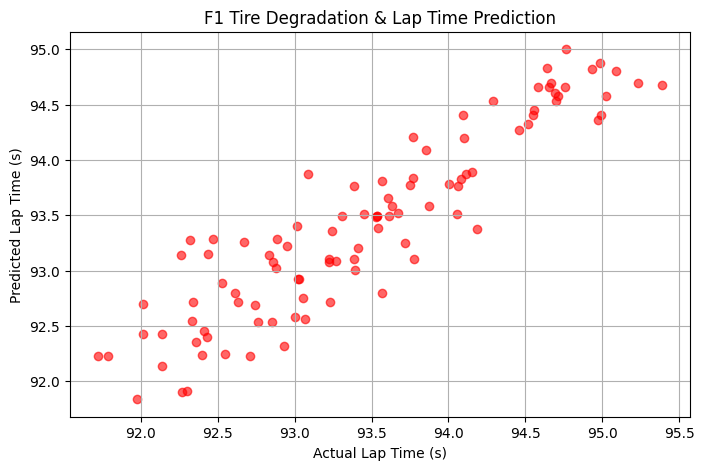

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Create a simulated F1 tire degradation & lap time dataset
np.random.seed(42)
n_samples = 500

tyre_life = np.random.randint(1, 35, size=n_samples)
compound_encoded = np.random.choice([0, 1, 2], size=n_samples) # 0: Soft, 1: Medium, 2: Hard
stint = np.random.randint(1, 4, size=n_samples)

# Simulate lap times (Base time + tire wear penalty + compound difference + random noise)
base_time = 92.5
lap_time_seconds = base_time + (tyre_life * 0.08) - (compound_encoded * 0.4) + np.random.normal(0, 0.3, size=n_samples)

df = pd.DataFrame({
    'TyreLife': tyre_life,
    'CompoundEncoded': compound_encoded,
    'Stint': stint,
    'LapTimeSeconds': lap_time_seconds
})

print(f"Dataset shape: {df.shape}")
print(df.head())

# 2. Define Features (X) and Target (y)
X = df[['TyreLife', 'CompoundEncoded', 'Stint']]
y = df['LapTimeSeconds']

# 3. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train Machine Learning Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Evaluate
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f"\nModel MAE Error: {mae:.3f} seconds")

# 6. Feature Importance
for feature, importance in zip(X.columns, model.feature_importances_):
    print(f"Feature '{feature}' Importance: {importance:.4f}")

# 7. Plot Results
plt.figure(figsize=(8, 5))
plt.scatter(y_test, predictions, alpha=0.6, color='red')
plt.xlabel("Actual Lap Time (s)")
plt.ylabel("Predicted Lap Time (s)")
plt.title("F1 Tire Degradation & Lap Time Prediction")
plt.grid(True)
plt.show()
